# Curve of growth -- from equivalent widths back to N and b

Goal: validate `cog.theoretical_ew` (the equivalent width predicted
for a given column density and Doppler parameter) and `cog.fit_cog`
(the inverse: recover `logN` and `b` from the measured EWs of several
lines of one species).

The fit needs lines of the same species with very different strengths,
so the tests use the FeII and SiII lines from `linelist.py` (real
atomic data from Verner, Verner & Ferland 1996) instead of the single
CIV-like test line of the earlier notebooks.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spectral_diag.core import C_KMS, Absorber
from spectral_diag.linelist import get_lines
from spectral_diag.profiles import TAU0_CONST, A_CONST
from spectral_diag.io import make_synthetic
from spectral_diag.ew import measure_ew
from spectral_diag.cog import theoretical_ew, fit_cog

feii = get_lines("FeII")
siii = {line.name: line for line in get_lines("SiII")}

print(f"{'line':10s} {'wave_rest':>10s} {'f':>9s} {'gamma':>10s} {'f*lambda':>9s}")
for line in feii:
    print(f"{line.name:10s} {line.wave_rest:10.4f} {line.f:9.5f} {line.gamma:10.3e} {line.f * line.wave_rest:9.1f}")

line        wave_rest         f      gamma  f*lambda
FeII 1608   1608.4511   0.08920  3.812e+08     143.5
FeII 2344   2344.2139   0.12600  2.542e+08     295.4
FeII 2367   2367.5905   0.00425  3.293e+08      10.1
FeII 2374   2374.4612   0.05270  3.304e+08     125.1
FeII 2382   2382.7652   0.34300  3.350e+08     817.3
FeII 2586   2586.6500   0.05480  2.864e+08     141.7
FeII 2600   2600.1729   0.24000  2.892e+08     624.0


The seven FeII lines span a factor of 80 in `f * lambda`, which is
what sets the optical depth at fixed N. That range is what lets one
cloud put some lines on the linear part of the curve and others on the
flat part at the same time.

## Test 1 -- `theoretical_ew` against the two closed forms

- Weak line: `W = TAU0_CONST * sqrt(pi) * N * f * lambda^2 / c`
  (derived in the notes, checked in notebook 02).
- Strongly damped line: only the Lorentzian wings matter,
  `tau = tau0 * a / (sqrt(pi) x^2)`, and the integral can be done by
  hand: `W = 2 * (lambda * b / c) * sqrt(sqrt(pi) * tau0 * a)`. Since
  `tau0 * a` goes as `1/b^2`, `b` cancels and `W` goes as `sqrt(N)`.

In [2]:
weak = next(line for line in feii if line.name == "FeII 2367")
strong = next(line for line in feii if line.name == "FeII 2382")
b = 10.0

W_weak = theoretical_ew(weak, 11.0, b)
W_linear = TAU0_CONST * np.sqrt(np.pi) * 1e11 * weak.f * weak.wave_rest**2 / C_KMS
print(f"linear regime : theoretical_ew / closed form - 1 = {W_weak / W_linear - 1:+.2e}")

tau0 = TAU0_CONST * 1e21 * strong.f * strong.wave_rest / b
a = A_CONST * strong.gamma * strong.wave_rest / b
W_strong = theoretical_ew(strong, 21.0, b)
W_damped = 2 * strong.wave_rest * b / C_KMS * np.sqrt(np.sqrt(np.pi) * tau0 * a)
print(f"damped regime : theoretical_ew / closed form - 1 = {W_strong / W_damped - 1:+.2e}")

assert abs(W_weak / W_linear - 1) < 1e-3
assert abs(W_strong / W_damped - 1) < 1e-3
print("PASS: theoretical_ew matches both closed forms.")

linear regime : theoretical_ew / closed form - 1 = -5.36e-05
damped regime : theoretical_ew / closed form - 1 = +3.14e-05
PASS: theoretical_ew matches both closed forms.


## Test 2 -- the curve of growth itself

Plotted the classic way: `W / lambda` against `N * f * lambda`. In
these variables every line of a species falls on the same curve for a
given `b` (as long as damping is unimportant), which is why several
lines together can pin down both `N` and `b`. The points are the seven
FeII lines for one cloud with `logN = 14.5`, `b = 10 km/s`.

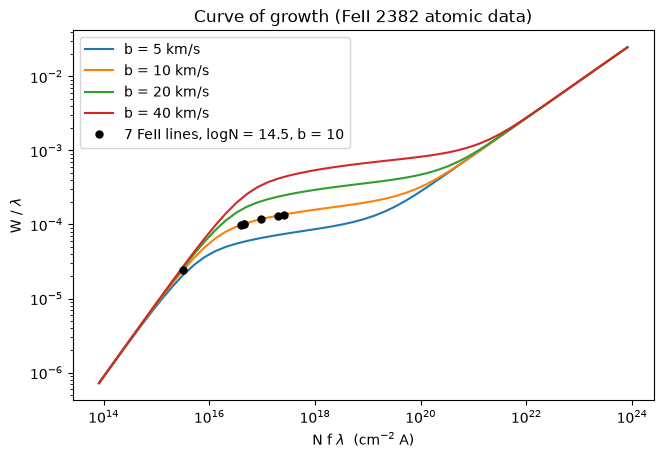

slope at low N : 0.988 (expected 1)
slope at high N: 0.500 (expected 0.5)
PASS: W ~ N at low N and W ~ sqrt(N) at high N.


In [3]:
logNs = np.arange(11.0, 21.01, 0.2)
plt.figure(figsize=(7.5, 4.8))
for b_curve in [5.0, 10.0, 20.0, 40.0]:
    W = theoretical_ew(strong, logNs, b_curve)
    plt.loglog(10**logNs * strong.f * strong.wave_rest, W / strong.wave_rest, label=f"b = {b_curve:.0f} km/s")

logN_cloud, b_cloud = 14.5, 10.0
x_pts = [10**logN_cloud * line.f * line.wave_rest for line in feii]
y_pts = [theoretical_ew(line, logN_cloud, b_cloud) / line.wave_rest for line in feii]
plt.loglog(x_pts, y_pts, "ko", ms=5, label="7 FeII lines, logN = 14.5, b = 10")

plt.xlabel(r"N f $\lambda$  (cm$^{-2}$ A)")
plt.ylabel(r"W / $\lambda$")
plt.title("Curve of growth (FeII 2382 atomic data)")
plt.legend()
plt.show()

W10 = theoretical_ew(strong, logNs, 10.0)
slope_low = np.polyfit(logNs[:5], np.log10(W10[:5]), 1)[0]
slope_high = np.polyfit(logNs[-5:], np.log10(W10[-5:]), 1)[0]
print(f"slope at low N : {slope_low:.3f} (expected 1)")
print(f"slope at high N: {slope_high:.3f} (expected 0.5)")
assert abs(slope_low - 1) < 0.02 and abs(slope_high - 0.5) < 0.02
print("PASS: W ~ N at low N and W ~ sqrt(N) at high N.")

The curves coincide at low N (no dependence on `b`), separate on
the flat part (larger `b` saturates later), and merge again at high N
(damping wings, no dependence on `b`). The seven points sit on the
`b = 10` curve and straddle the bend, which is the favourable case for
a fit.

## Test 3 -- recover injected (logN, b) from a noise-free spectrum

The EWs here come from `make_synthetic` + `measure_ew`, i.e. from
integrating a spectrum in wavelength, not from `theoretical_ew`. So
the fit is checked against an independent calculation.

In [4]:
def measure_all(spec, lines, z, half_kms=None, half_A=None, with_error=True):
    """EW of every line, in a window given in km/s or in Angstrom."""
    ews = {}
    for line in lines:
        centre = line.wave_rest * (1 + z)
        half = half_A if half_A is not None else centre * half_kms / C_KMS
        ews[line.name] = measure_ew(spec.wave, spec.flux, spec.continuum,
                                    error=spec.error if with_error else None,
                                    wave_min=centre - half, wave_max=centre + half)
    return ews


z = 1.0
wave = np.arange(3200.0, 5220.0, 0.02)
print(f"{'true logN':>9s} {'true b':>7s} | {'fit logN':>9s} {'fit b':>7s}")
for logN_true, b_true in [(12.5, 10.0), (14.5, 10.0), (15.5, 25.0)]:
    spec = make_synthetic(wave, [Absorber("FeII", z, logN_true, b_true, feii)])
    ews = measure_all(spec, feii, z, half_kms=150.0, with_error=False)
    ews = {name: (W, 0.003) for name, (W, _) in ews.items()}  # nominal error bar
    fit = fit_cog(feii, ews, z=z)
    print(f"{logN_true:9.2f} {b_true:7.1f} | {fit['logN']:9.3f} {fit['b']:7.2f}")
    assert abs(fit["logN"] - logN_true) < 0.01
    if logN_true > 13:
        assert abs(fit["b"] - b_true) < 0.1
print("PASS: logN recovered to 0.01 dex; b recovered once some lines are saturated.")

true logN  true b |  fit logN   fit b
    12.50    10.0 |    12.500   10.00
    14.50    10.0 |    14.500   10.00
    15.50    25.0 |    15.501   24.97
PASS: logN recovered to 0.01 dex; b recovered once some lines are saturated.


In the first case (`logN = 12.5`) every line is close to the
linear regime, where `W` does not depend on `b`. The fit returns the
right `b` here only because the data are noise-free; with real error
bars `b` is unconstrained (the reported `b_err` is larger than `b`
itself). This is a property of the method, not a bug.

### The damped regime, and why the window matters

For a damped line the absorption extends tens of Angstrom from the
centre. Three well separated SiII lines are used so that wide windows
do not overlap.

In [5]:
damped_lines = [siii[name] for name in ("SiII 1260", "SiII 1526", "SiII 1808")]
logN_true, b_true = 18.5, 15.0
wave_si = np.arange(1100.0, 1960.0, 0.01)
spec = make_synthetic(wave_si, [Absorber("SiII", 0.0, logN_true, b_true, damped_lines)])

for half_A in [20.0, 100.0]:
    ews = measure_all(spec, damped_lines, 0.0, half_A=half_A, with_error=False)
    ews = {name: (W, 0.01) for name, (W, _) in ews.items()}
    fit = fit_cog(damped_lines, ews)
    print(f"window +-{half_A:3.0f} A: W(SiII 1260) = {ews['SiII 1260'][0]:.3f} A"
          f"  ->  logN = {fit['logN']:.3f}, b = {fit['b']:.2f}")
print(f"truth          : W(SiII 1260) = {theoretical_ew(siii['SiII 1260'], logN_true, b_true):.3f} A"
      f"  ->  logN = {logN_true:.3f}, b = {b_true:.2f}")

assert abs(fit["logN"] - logN_true) < 0.02 and abs(fit["b"] - b_true) < 0.5
print("PASS: with a wide enough window, the damped case is recovered too.")

window +- 20 A: W(SiII 1260) = 4.924 A  ->  logN = 18.466, b = 15.25
window +-100 A: W(SiII 1260) = 5.092 A  ->  logN = 18.494, b = 15.13
truth          : W(SiII 1260) = 5.133 A  ->  logN = 18.500, b = 15.00
PASS: with a wide enough window, the damped case is recovered too.


A +-20 A window cuts off part of the wings of SiII 1260, the EW
comes out about 4% too small, and `logN` is biased low by about 0.03
dex. On real data the window is limited by neighbouring lines and by
how well the continuum is known, so this bias is a real limitation of
the EW method for damped lines (profile fitting handles them better).

## Test 4 -- noisy spectra: is the fit unbiased, and are its error bars right?

Same cloud (`logN = 14.5`, `b = 10 km/s`, `z = 1`) observed 100 times
with independent noise at S/N = 50. Three things should hold: the mean
of the fitted values is the truth, the scatter of the fitted values
equals the error bar the fit reports, and about 68% of the fits fall
within one reported sigma of the truth.

In [ ]:
logN_true, b_true, snr = 14.5, 10.0, 50.0
cloud = Absorber("FeII", z, logN_true, b_true, feii)
rng = np.random.default_rng(1)

fits = []
for _ in range(100):
    spec = make_synthetic(wave, [cloud], snr=snr, rng=rng)
    fits.append(fit_cog(feii, measure_all(spec, feii, z, half_kms=120.0), z=z))

logN_fit = np.array([f["logN"] for f in fits])
b_fit = np.array([f["b"] for f in fits])
logN_err = np.array([f["logN_err"] for f in fits])
b_err = np.array([f["b_err"] for f in fits])
chi2 = np.array([f["chi2"] for f in fits])

print(f"logN: mean {logN_fit.mean():.3f} (truth {logN_true}), scatter {logN_fit.std():.3f}, mean reported error {logN_err.mean():.3f}")
print(f"b   : mean {b_fit.mean():.2f} (truth {b_true}), scatter {b_fit.std():.2f}, mean reported error {b_err.mean():.2f}")
print(f"fraction within 1 sigma of the truth: logN {np.mean(abs(logN_fit - logN_true) < logN_err):.2f}, b {np.mean(abs(b_fit - b_true) < b_err):.2f}")
print(f"mean chi2 = {chi2.mean():.2f} for {fits[0]['dof']} degrees of freedom")

plt.figure(figsize=(6.5, 4.5))
plt.errorbar(logN_fit, b_fit, xerr=logN_err, yerr=b_err, fmt="o", ms=3, alpha=0.35, label="100 noisy fits")
plt.plot(logN_true, b_true, "r*", ms=16, label="truth")
plt.xlabel("fitted logN")
plt.ylabel("fitted b (km/s)")
plt.title(f"FeII, 7 lines, S/N = {snr:.0f}")
plt.legend()
plt.show()

assert abs(logN_fit.mean() - logN_true) < 0.01 and abs(b_fit.mean() - b_true) < 0.05
assert 0.7 < logN_fit.std() / logN_err.mean() < 1.3 and 0.7 < b_fit.std() / b_err.mean() < 1.3
print("PASS: the fit is unbiased and its error bars match the actual scatter.")

The cloud of points is tilted: fits with a higher `logN` have a
lower `b`. That anticorrelation is the N-b degeneracy of the flat part
of the curve, kept small here by the weak lines.

## Test 5 -- what happens with saturated lines only

Same kind of cloud (`logN = 15`, `b = 10`), but compare the chi-square
surface when only the three strongest lines are measured with the one
obtained from all seven. Contours are at delta chi2 = 2.30 and 6.18
(68% and 95% for two parameters), for an EW error of 0.02 A on each
line.

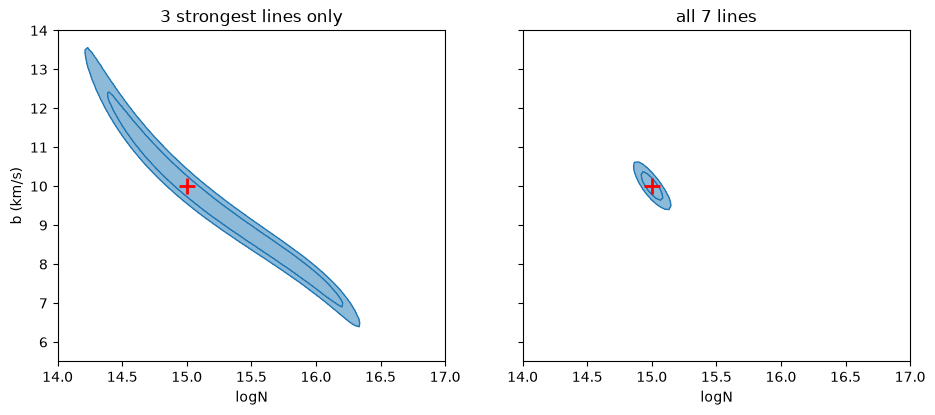

3 strongest lines only  : logN allowed at 68% over a range of 1.80 dex
all 7 lines             : logN allowed at 68% over a range of 0.13 dex
PASS: saturated lines alone leave logN uncertain by more than 1 dex; adding weak lines fixes it.


In [ ]:
logN_true, b_true, ew_err = 15.0, 10.0, 0.02
strong_only = [line for line in feii if line.name in ("FeII 2344", "FeII 2382", "FeII 2600")]

grid_logN = np.linspace(14.0, 17.0, 91)
grid_b = np.linspace(5.5, 14.0, 86)
GN, GB = np.meshgrid(grid_logN, grid_b, indexing="ij")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
spans = {}
for ax, (title, subset) in zip(axes, [("3 strongest lines only", strong_only), ("all 7 lines", feii)]):
    chi2_map = sum(((theoretical_ew(line, GN, GB, z) - theoretical_ew(line, logN_true, b_true, z)) / ew_err) ** 2
                   for line in subset)
    ax.contourf(grid_logN, grid_b, chi2_map.T, levels=[0, 2.30, 6.18], colors=["C0", "C0"], alpha=0.5)
    ax.contour(grid_logN, grid_b, chi2_map.T, levels=[2.30, 6.18], colors="C0", linewidths=1)
    ax.plot(logN_true, b_true, "r+", ms=12, mew=2)
    ax.set_xlabel("logN")
    ax.set_title(title)
    allowed = grid_logN[chi2_map.min(axis=1) < 2.30]
    spans[title] = allowed.max() - allowed.min()
axes[0].set_ylabel("b (km/s)")
plt.show()

for title, span in spans.items():
    print(f"{title:24s}: logN allowed at 68% over a range of {span:.2f} dex")
assert spans["3 strongest lines only"] > 1.0 and spans["all 7 lines"] < 0.3
print("PASS: saturated lines alone leave logN uncertain by more than 1 dex; adding weak lines fixes it.")

With saturated lines only, a whole band of (logN, b) pairs fits
equally well: a slightly smaller `b` with a much larger `N` gives the
same equivalent widths. The band even contains two separate minima,
which is why `fit_cog` refines from several starting points. The
reported `logN_err` comes from the curvature at the best fit and does
not describe a band like this; a chi-square map (later in
`uncertainty.py`) is the honest error estimate there.

## Limits of what is tested here

- One cloud, one velocity component. Real absorbers often have several
  components; a single-cloud fit then typically returns an effective
  `b` larger than that of any component and can underestimate `N`.
- No instrumental broadening. EWs are mostly insensitive to it, but
  blending with neighbouring lines is not modelled.
- The continuum is known exactly (flat, equal to 1).
- `gamma` for FeII only includes decays listed in the Verner table.

## Next step

`continuum.py`, so that the same chain runs on a spectrum whose
continuum has to be fitted first.